# Data Cleaning + EDA + Data Modelling

# Harbourline Finance — Credit Risk Analysis

## Cleaning, Exploratory Data Analysis & PD Modelling

This notebook cleans and analyses Harbourline Finance's historical
credit portfolio, develops a Probability of Default (PD) model,
evaluates model performance using an out-of-time validation period,
and applies the model to Q1 2025 applications.

### Analytical flow

Raw Data
→ Data Cleaning
→ Exploratory Data Analysis
→ Feature Engineering
→ PD Modelling
→ Model Validation
→ Expected Loss
→ Credit Policy Simulation
→ Q1 2025 Scoring

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(PROJECT_ROOT)

C:\Users\Administrator\Desktop\harborline_credit_risk


In [3]:
#libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import load_table

In [5]:
#loading and creating copies
loans = load_table("loans_2023_2024")
applications = load_table("applications_2025q1")

loans_clean = loans.copy()
applications_clean = applications.copy()

In [6]:
print("Historical loans:", loans_clean.shape)
print("Q1 2025 applications:", applications_clean.shape)

Historical loans: (11582, 21)
Q1 2025 applications: (3000, 18)


In [7]:
loans_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 11582 entries, 0 to 11581
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   loan_id             11582 non-null  str    
 1   application_month   11582 non-null  str    
 2   age                 11582 non-null  int64  
 3   employment_type     11582 non-null  str    
 4   employment_years    11210 non-null  float64
 5   annual_income       11349 non-null  float64
 6   home_ownership      11582 non-null  str    
 7   bureau_score        11582 non-null  int64  
 8   credit_utilisation  11582 non-null  float64
 9   delinquencies_2y    11582 non-null  int64  
 10  inquiries_6m        11582 non-null  int64  
 11  loan_purpose        11582 non-null  str    
 12  loan_amount         11582 non-null  float64
 13  term_months         11582 non-null  int64  
 14  debt_to_income      11582 non-null  float64
 15  channel             11582 non-null  str    
 16  region         

In [8]:
applications_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   application_id      3000 non-null   str    
 1   application_month   3000 non-null   str    
 2   age                 3000 non-null   int64  
 3   employment_type     3000 non-null   str    
 4   employment_years    2884 non-null   float64
 5   annual_income       2943 non-null   float64
 6   home_ownership      3000 non-null   str    
 7   bureau_score        3000 non-null   int64  
 8   credit_utilisation  3000 non-null   float64
 9   delinquencies_2y    3000 non-null   int64  
 10  inquiries_6m        3000 non-null   int64  
 11  loan_purpose        3000 non-null   str    
 12  loan_amount         3000 non-null   float64
 13  term_months         3000 non-null   int64  
 14  debt_to_income      3000 non-null   float64
 15  channel             3000 non-null   str    
 16  region           

In [10]:
print("Duplicate loan Ids:", loans_clean["loan_id"].duplicated().sum())

print("Duplicat complete rows:", loans_clean.duplicated().sum())

Duplicate loan Ids: 0
Duplicat complete rows: 0


In [12]:
print("Duplicate application IDs:", applications_clean["application_id"].duplicated().sum())

print("Duplicate complete rows:", applications_clean.duplicated().sum())

Duplicate application IDs: 0
Duplicate complete rows: 0


In [13]:
missing_summary = pd.DataFrame({
    "missing_count": loans_clean.isna().sum(),
    "missing_pct": loans_clean.isna().mean() * 100
}).sort_values(
    "missing_pct",
    ascending=False
)

missing_summary

,missing_count,missing_pct
employment_years,372,3.211881
annual_income,233,2.011742
loan_id,0,0.000000
age,0,0.000000
application_month,0,0.000000
employment_type,0,0.000000
home_ownership,0,0.000000
bureau_score,0,0.000000
credit_utilisation,0,0.000000
delinquencies_2y,0,0.000000


In [14]:
missing_summary[missing_summary["missing_count"] > 0]

,missing_count,missing_pct
employment_years,372,3.211881
annual_income,233,2.011742


In [15]:
missing_summary2 = pd.DataFrame({
    "missing_count": applications_clean.isna().sum(),
    "missing_pct": applications_clean.isna().mean() * 100
}).sort_values(
    "missing_pct",
    ascending=False
)

missing_summary2

,missing_count,missing_pct
employment_years,116,3.866667
annual_income,57,1.900000
application_month,0,0.000000
application_id,0,0.000000
employment_type,0,0.000000
age,0,0.000000
home_ownership,0,0.000000
bureau_score,0,0.000000
credit_utilisation,0,0.000000
delinquencies_2y,0,0.000000


In [16]:
missing_summary2[missing_summary2["missing_count"] > 0]

,missing_count,missing_pct
employment_years,116,3.866667
annual_income,57,1.900000


In [17]:
invalid_age = loans_clean[
    (loans_clean["age"] < 18) |
    (loans_clean["age"] > 100)
]

invalid_age[["loan_id", "age"]]

,loan_id,age
917,HL100918,999
1238,HL101239,0
1267,HL101268,999
1400,HL101401,0
1442,HL101443,0
2158,HL102159,0
3153,HL103154,0
3458,HL103459,0
3876,HL103877,999
4317,HL104318,0


In [23]:
len(invalid_age)

39

In [24]:
loans_clean[
    loans_clean["annual_income"] < 0
][["loan_id", "annual_income"]]

,loan_id,annual_income


In [25]:
loans_clean[
    loans_clean["loan_amount"] <= 0
][["loan_id", "loan_amount"]]

,loan_id,loan_amount


In [26]:
loans_clean[
    loans_clean["employment_years"] < 0
][["loan_id", "employment_years"]]

,loan_id,employment_years


In [27]:
#Inspecting categorical incosnsitencies
categorical_cols = [
    "employment_type",
    "home_ownership",
    "loan_purpose",
    "channel",
    "region"
]

for col in categorical_cols:
    print(f"\n===== {col} =====")
    print(loans_clean[col].value_counts(dropna=False))


===== employment_type =====
employment_type
Salaried         6415
Self-employed    2337
Contract         1672
Informal         1158
Name: count, dtype: int64

===== home_ownership =====
home_ownership
Rent        5275
Mortgage    2860
Own         1732
Family      1715
Name: count, dtype: int64

===== loan_purpose =====
loan_purpose
Debt consolidation    3950
Home improvement      1773
Vehicle               1363
Business              1199
Other                 1188
Education             1154
Medical                955
Name: count, dtype: int64

===== channel =====
channel
Online    5792
Branch    3498
Broker    2292
Name: count, dtype: int64

===== region =====
region
Metro South    2947
Metro North    2878
Coastal        2257
Inland         2115
Rural          1385
Name: count, dtype: int64


In [28]:
#distribution check
loans_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
age,11582.0,38.468486,44.118614,0.0000,29.0000,36.0000,44.0000,999.0000
employment_years,11210.0,4.943684,3.487907,0.0000,2.4000,4.2000,6.7000,30.7000
annual_income,11349.0,34319.393779,18475.928860,3900.0000,21500.0000,30000.0000,42700.0000,208300.0000
bureau_score,11582.0,644.185892,51.017322,540.0000,606.0000,642.0000,679.0000,820.0000
credit_utilisation,11582.0,0.468845,0.209882,0.0000,0.3090,0.4530,0.6170,1.1310
delinquencies_2y,11582.0,0.737178,1.081194,0.0000,0.0000,0.0000,1.0000,9.0000
inquiries_6m,11582.0,1.196512,1.098182,0.0000,0.0000,1.0000,2.0000,7.0000
loan_amount,11582.0,9085.857365,6273.229233,1000.0000,4600.0000,7500.0000,11700.0000,40000.0000
term_months,11582.0,28.632361,11.703120,12.0000,24.0000,24.0000,36.0000,48.0000
debt_to_income,11582.0,0.341958,0.147870,0.0330,0.2290,0.3240,0.4380,0.8780


In [29]:
loans_clean[
    loans_clean["employment_years"] > loans_clean["age"]
][[
    "loan_id",
    "age",
    "employment_years"
]]

,loan_id,age,employment_years
1238,HL101239,0,3.5
1400,HL101401,0,2.4
1442,HL101443,0,1.0
2158,HL102159,0,2.2
3153,HL103154,0,1.2
3458,HL103459,0,8.1
4317,HL104318,0,6.5
4424,HL104425,0,6.0
4596,HL104597,0,12.7
5654,HL105655,0,9.6


### Logical Consistency Findings

The employment-history consistency check identified 19 records where
employment_years exceeds age.

Further inspection shows two underlying issues:

1. Several records have age = 0. These are invalid age values and
   should be treated as missing during the cleaning stage.

2. A smaller number of records have plausible-looking ages but
   employment_years greater than age. These represent logical
   inconsistencies requiring investigation before modelling.

No records are removed at the audit stage.

In [30]:
employment_age_issue = loans_clean[
    (loans_clean["age"] >= 18) &
    (loans_clean["age"] <= 100) &
    (loans_clean["employment_years"] > loans_clean["age"])
]

print("Employment-age inconsistencies:", len(employment_age_issue))

employment_age_issue[
    ["loan_id", "age", "employment_years"]
]

Employment-age inconsistencies: 3


,loan_id,age,employment_years
6772,HL106773,19,20.6
7459,HL107460,27,30.5
11225,HL111226,19,19.1


### Logical Consistency Findings

The logical consistency audit identified two issues:

| Issue | Count | Classification | Planned treatment |
|---|---:|---|---|
| Invalid age values | 39 | Data quality | Convert invalid ages to missing |
| Employment years greater than age for valid-age records | 3 | Logical inconsistency | Treat employment_years as invalid/missing |

The 39 invalid age records are retained rather than removed because the
issue affects the age field rather than necessarily invalidating the
entire loan record.

Three records have plausible ages but employment_years values that are
logically impossible. These employment history values will be treated
as invalid during the cleaning stage.

No records are modified or deleted during the audit stage.

In [31]:
loans_clean.describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
age,11582.0,38.468486,44.118614,0.0000,19.000000,19.0000,29.0000,36.0000,44.0000,55.0000,63.00000,999.0000
employment_years,11210.0,4.943684,3.487907,0.0000,0.400000,0.9000,2.4000,4.2000,6.7000,11.6000,16.09100,30.7000
annual_income,11349.0,34319.393779,18475.928860,3900.0000,9348.000000,13100.0000,21500.0000,30000.0000,42700.0000,69200.0000,97500.00000,208300.0000
bureau_score,11582.0,644.185892,51.017322,540.0000,546.000000,563.0000,606.0000,642.0000,679.0000,732.0000,766.00000,820.0000
credit_utilisation,11582.0,0.468845,0.209882,0.0000,0.066000,0.1470,0.3090,0.4530,0.6170,0.8350,0.95619,1.1310
delinquencies_2y,11582.0,0.737178,1.081194,0.0000,0.000000,0.0000,0.0000,0.0000,1.0000,3.0000,4.00000,9.0000
inquiries_6m,11582.0,1.196512,1.098182,0.0000,0.000000,0.0000,0.0000,1.0000,2.0000,3.0000,4.00000,7.0000
loan_amount,11582.0,9085.857365,6273.229233,1000.0000,1400.000000,2300.0000,4600.0000,7500.0000,11700.0000,21400.0000,31200.00000,40000.0000
term_months,11582.0,28.632361,11.703120,12.0000,12.000000,12.0000,24.0000,24.0000,36.0000,48.0000,48.00000,48.0000
debt_to_income,11582.0,0.341958,0.147870,0.0330,0.085000,0.1300,0.2290,0.3240,0.4380,0.6150,0.71719,0.8780


In [32]:
high_utilisation = loans_clean[
    loans_clean["credit_utilisation"] > 1
]

print("Utilisation > 100%:", len(high_utilisation))

high_utilisation[
    ["loan_id", "credit_utilisation", "bureau_score", "loan_amount"]
]

Utilisation > 100%: 44


,loan_id,credit_utilisation,bureau_score,loan_amount
121,HL100122,1.087,555,13100.0
274,HL100275,1.017,596,2400.0
360,HL100361,1.057,554,14600.0
438,HL100439,1.053,565,16700.0
461,HL100462,1.047,567,3900.0
811,HL100812,1.001,573,17400.0
1007,HL101008,1.032,569,15600.0
1187,HL101188,1.054,573,3700.0
1238,HL101239,1.063,544,1600.0
1584,HL101585,1.051,554,4900.0


### Credit Utilisation

44 historical loans have credit utilisation above 100%.

The maximum observed value is approximately 113.1%. The case materials
do not define 100% as a hard upper validity boundary, and the observed
values are not sufficiently extreme to establish that they are data
errors.

These observations will therefore be retained without capping or
removal. Their relationship with default will be examined during EDA.

In [33]:
high_employment = loans_clean[
    loans_clean["employment_years"] > 20
]

print("Records with employment_years > 20:", len(high_employment))

high_employment[
    ["loan_id", "age", "employment_years", "employment_type"]
]

Records with employment_years > 20: 34


,loan_id,age,employment_years,employment_type
578,HL100579,40,20.9,Informal
600,HL100601,34,20.7,Salaried
872,HL100873,36,20.7,Informal
931,HL100932,31,20.9,Salaried
1151,HL101152,52,23.0,Salaried
2062,HL102063,48,23.1,Salaried
2175,HL102176,48,25.5,Salaried
2638,HL102639,41,24.2,Salaried
2741,HL102742,37,21.5,Salaried
3022,HL103023,44,21.9,Salaried


In [34]:
loans_clean["default_12m"].value_counts(dropna=False)

default_12m
0    10499
1     1083
Name: count, dtype: int64

In [35]:
loans_clean["default_12m"].unique()

array([0, 1])

In [36]:
loans_clean["default_12m"].value_counts(
    normalize=True,
    dropna=False
) * 100

default_12m
0    90.649283
1     9.350717
Name: proportion, dtype: float64

### Target Integrity Findings

The target variable, `default_12m`, contains two observed values:
0 and 1.

- Non-defaults: 10,499 (90.65%)
- Defaults: 1,083 (9.35%)
- Total historical loans: 11,582

The target is consistent with a binary classification problem.
The observed default rate is 9.35%, and the target is imbalanced.

Model evaluation should therefore consider discrimination and
probability calibration rather than accuracy alone.

The target values have been inspected; no target transformations
have been made at this stage.

In [37]:
print("Missing target values:", loans_clean["default_12m"].isna().sum())

Missing target values: 0


### Leakage Assessment

The purpose of this assessment is to identify variables that should not be used as predictors because they represent the target itself or information observed after the credit decision or loan outcome.

- `default_12m` is the target variable and must not be included among the predictors.
- `ead_at_default` represents exposure at default and is reserved for loss analysis.
- `recovery_amount` represents recovery information and is reserved for loss analysis.

These variables will be excluded from the PD model's predictor set. They may be used later for expected-loss and loss-severity analysis where appropriate.

Other variables will be assessed according to whether they would have been available at application time.


In [38]:
print("Historical dataset columns:")
for col in loans_clean.columns:
    print("-", col)

Historical dataset columns:
- loan_id
- application_month
- age
- employment_type
- employment_years
- annual_income
- home_ownership
- bureau_score
- credit_utilisation
- delinquencies_2y
- inquiries_6m
- loan_purpose
- loan_amount
- term_months
- debt_to_income
- channel
- region
- interest_rate
- default_12m
- ead_at_default
- recovery_amount


### Leakage Assessment

The historical dataset contains three variables that must not be used as predictors in the probability-of-default (PD) model:

- `default_12m`: the target variable.
- `ead_at_default`: an outcome-related exposure measure reserved for loss analysis.
- `recovery_amount`: a recovery measure reserved for loss analysis.

The `loan_id` column will also be excluded from the predictor set because it is an identifier rather than a meaningful risk characteristic.

The `interest_rate` column requires further investigation. Its inclusion will depend on whether it was known at the time of the credit decision or assigned after the decision based on the lender's existing risk assessment.

The remaining candidate predictors will be evaluated for availability at application time. This prevents the model from using information that would not have been available when assessing a new applicant.

In [39]:
loans_clean.groupby("default_12m")["interest_rate"].agg(
    ["count", "mean", "median", "min", "max"]
).round(4)

,count,mean,median,min,max
default_12m,,,,,
0,10499,0.1788,0.1759,0.0738,0.3098
1,1083,0.2296,0.2331,0.0975,0.3141


### Interest Rate Leakage Assessment

The mean interest rate for defaulted loans was 22.96%, compared with 17.88% for non-defaulted loans. The median interest rates were 23.31% and 17.59%, respectively.

This indicates an association between interest rates and observed default outcomes. However, the descriptive analysis alone cannot establish causation or confirm data leakage.

Because the timing and assignment mechanism of `interest_rate` have not yet been verified, the variable will be excluded from the initial PD model to reduce the risk of using information influenced by the existing credit decision or risk-based pricing process. Its inclusion may be reconsidered if its availability at the intended decision point is confirmed.

In [40]:
# 2025_Q1 application dataset
print("2025 application columns:")
for col in applications_clean.columns:
    print("-", col)

2025 application columns:
- application_id
- application_month
- age
- employment_type
- employment_years
- annual_income
- home_ownership
- bureau_score
- credit_utilisation
- delinquencies_2y
- inquiries_6m
- loan_purpose
- loan_amount
- term_months
- debt_to_income
- channel
- region
- interest_rate


### Leakage Assessment and Dataset Comparison

The historical dataset contains the observed default target and post-outcome loss variables, while the Q1 2025 application dataset contains applications without observed default outcomes.

The following columns will be excluded from the initial PD model:

- `loan_id` and `application_id`: identifiers.
- `default_12m`: target variable, used only when training and evaluating the model.
- `ead_at_default` and `recovery_amount`: outcome-related variables reserved for loss analysis.
- `interest_rate`: temporarily excluded because its timing and assignment mechanism have not been verified.

The remaining candidate predictors are available in both datasets. Their suitability will be confirmed during cleaning and modelling.

The historical data will be used to train and validate the model. The Q1 2025 applications will be scored only after the historical model and preprocessing pipeline have been finalised.

## Cleaning

In [41]:
# Convert application_month to datetime
loans_clean["application_month"] = pd.to_datetime(loans_clean["application_month"], errors = "coerce")

applications_clean["application_month"] = pd.to_datetime(applications_clean["application_month"], errors = "coerce")

# Inspect the results
print("Historical application dates:")
print(loans_clean["application_month"].dtype)
print(loans_clean["application_month"].isna().sum(), "missing dates")
print(loans_clean["application_month"].min())
print(loans_clean["application_month"].max())

print("\nQ1 2025 application dates:")
print(applications_clean["application_month"].dtype)
print(applications_clean["application_month"].isna().sum(), "missing dates")
print(applications_clean["application_month"].min())
print(applications_clean["application_month"].max())

Historical application dates:
datetime64[us]
0 missing dates
2023-01-01 00:00:00
2024-06-01 00:00:00

Q1 2025 application dates:
datetime64[us]
0 missing dates
2025-01-01 00:00:00
2025-03-01 00:00:00


In [42]:
# Inspect invalid ages in both datasets
invalid_age_mask = lambda df: (df["age"] < 18) | (df["age"] > 100)

print("Historical invalid ages:")
print("Count:", invalid_age_mask(loans_clean).sum())
print(loans_clean.loc[invalid_age_mask(loans_clean), "age"].value_counts().sort_index())

print("\n2025 application invalid ages:")
print("Count:", invalid_age_mask(applications_clean).sum())
print(applications_clean.loc[invalid_age_mask(applications_clean), "age"].value_counts().sort_index())

Historical invalid ages:
Count: 39
age
0      16
999    23
Name: count, dtype: int64

2025 application invalid ages:
Count: 9
age
0      4
999    5
Name: count, dtype: int64


In [43]:
# Cleaning the ages
import numpy as np

# Define the plausible age range
MIN_AGE = 18
MAX_AGE = 100

# Replace invalid historical ages with missing values
loans_clean.loc[
    (loans_clean["age"] < MIN_AGE) |
    (loans_clean["age"] > MAX_AGE),
    "age"
] = np.nan

# Apply the same rule to Q1 2025 applications
applications_clean.loc[
    (applications_clean["age"] < MIN_AGE) |
    (applications_clean["age"] > MAX_AGE),
    "age"
] = np.nan

In [44]:
#Validating the cleaning
print("Historical dataset")
print("Missing ages:", loans_clean["age"].isna().sum())
print(
    "Remaining invalid ages:",
    ((loans_clean["age"] < 18) | (loans_clean["age"] > 100)).sum()
)

print("\nQ1 2025 applications")
print("Missing ages:", applications_clean["age"].isna().sum())
print(
    "Remaining invalid ages:",
    ((applications_clean["age"] < 18) | (applications_clean["age"] > 100)).sum()
)

Historical dataset
Missing ages: 39
Remaining invalid ages: 0

Q1 2025 applications
Missing ages: 9
Remaining invalid ages: 0


In [45]:
# employment years inconsitencies
# Check employment duration against age in both datasets
historical_employment_issue = loans_clean[
    loans_clean["age"].notna()
    & loans_clean["employment_years"].notna()
    & (loans_clean["employment_years"] > loans_clean["age"])
]

applications_employment_issue = applications_clean[
    applications_clean["age"].notna()
    & applications_clean["employment_years"].notna()
    & (applications_clean["employment_years"] > applications_clean["age"])
]

print("Historical inconsistencies:", len(historical_employment_issue))
print(
    historical_employment_issue[
        ["loan_id", "age", "employment_years"]
    ]
)

print("\n2025 application inconsistencies:", len(applications_employment_issue))
print(
    applications_employment_issue[
        ["application_id", "age", "employment_years"]
    ]
)

Historical inconsistencies: 3
        loan_id   age  employment_years
6772   HL106773  19.0              20.6
7459   HL107460  27.0              30.5
11225  HL111226  19.0              19.1

2025 application inconsistencies: 3
     application_id   age  employment_years
16         AP500017  22.0              22.4
1550       AP501551  23.0              25.0
2951       AP502952  19.0              23.0


In [46]:
# Historical dataset: invalidate inconsistent employment durations
loans_clean.loc[
    loans_clean["employment_years"] > loans_clean["age"],
    "employment_years"
] = np.nan

# Q1 2025 applications: apply the same rule
applications_clean.loc[
    applications_clean["employment_years"] > applications_clean["age"],
    "employment_years"
] = np.nan

In [47]:
print("Historical dataset")
print("Rows retained:", len(loans_clean))
print("Missing employment years:", loans_clean["employment_years"].isna().sum())
print(
    "Remaining inconsistencies:",
    (
        loans_clean["employment_years"].notna()
        & loans_clean["age"].notna()
        & (loans_clean["employment_years"] > loans_clean["age"])
    ).sum()
)

print("\nQ1 2025 applications")
print("Rows retained:", len(applications_clean))
print("Missing employment years:", applications_clean["employment_years"].isna().sum())
print(
    "Remaining inconsistencies:",
    (
        applications_clean["employment_years"].notna()
        & applications_clean["age"].notna()
        & (applications_clean["employment_years"] > applications_clean["age"])
    ).sum()
)

Historical dataset
Rows retained: 11582
Missing employment years: 375
Remaining inconsistencies: 0

Q1 2025 applications
Rows retained: 3000
Missing employment years: 119
Remaining inconsistencies: 0


### Invalid Ages and Employment Duration

Invalid ages outside the range of 18–100 were replaced with missing values in both datasets. This affected 39 historical records and 9 Q1 2025 applications.

A logical consistency check also identified three records in each dataset where employment duration exceeded the recorded age. The inconsistent `employment_years` values were replaced with missing values, while all applicant records were retained.

After correction, no age/employment-duration inconsistencies remained among records where both values were available. Missing values will be handled during the modelling preprocessing stage, with imputation parameters fitted on the training data only.

In [48]:
# Historical dataset: missing-value audit
historical_missing = pd.DataFrame({
    "missing_count": loans_clean.isna().sum(),
    "missing_percent": (
        loans_clean.isna().mean() * 100
    ).round(2)
})

print("HISTORICAL DATASET")
display(
    historical_missing.sort_values(
        "missing_count",
        ascending=False
    )
)

# Q1 2025 applications: missing-value audit
applications_missing = pd.DataFrame({
    "missing_count": applications_clean.isna().sum(),
    "missing_percent": (
        applications_clean.isna().mean() * 100
    ).round(2)
})

print("\nQ1 2025 APPLICATIONS")
display(
    applications_missing.sort_values(
        "missing_count",
        ascending=False
    )
)

HISTORICAL DATASET


,missing_count,missing_percent
employment_years,375,3.24
annual_income,233,2.01
age,39,0.34
application_month,0,0.00
loan_id,0,0.00
employment_type,0,0.00
home_ownership,0,0.00
bureau_score,0,0.00
credit_utilisation,0,0.00
delinquencies_2y,0,0.00



Q1 2025 APPLICATIONS


,missing_count,missing_percent
employment_years,119,3.97
annual_income,57,1.90
age,9,0.30
application_id,0,0.00
application_month,0,0.00
employment_type,0,0.00
home_ownership,0,0.00
bureau_score,0,0.00
credit_utilisation,0,0.00
delinquencies_2y,0,0.00


### Missing-Value Assessment

The missing-value audit identified three columns requiring preprocessing: `age`, `employment_years`, and `annual_income`.

In the historical dataset, missingness was 0.34% for age (39 records), 3.24% for employment years (375 records), and 2.01% for annual income (233 records). In the Q1 2025 application dataset, the corresponding proportions were 0.30% (9 records), 3.97% (119 records), and 1.90% (57 records).

The missing employment-duration values include records invalidated during logical consistency checks, while missing ages include invalid values corrected during age validation.

No other columns contained missing values in either dataset. Applicant records will be retained. Missing values will be handled through a preprocessing pipeline, with imputation parameters fitted on the historical training data and reused for validation and 2025 scoring.

In [49]:
# Categorical inconsitencies
categorical_cols = [
    "employment_type",
    "home_ownership",
    "loan_purpose",
    "channel",
    "region",
]

for col in categorical_cols:
    print(f"\n{'=' * 12} {col} {'=' * 12}")

    print("Historical values:")
    print(loans_clean[col].value_counts(dropna=False).sort_index())

    print("\nQ1 2025 values:")
    print(applications_clean[col].value_counts(dropna=False).sort_index())


============ employment_type ============
Historical values:
employment_type
Contract         1672
Informal         1158
Salaried         6415
Self-employed    2337
Name: count, dtype: int64

Q1 2025 values:
employment_type
Contract          444
Informal          305
Salaried         1662
Self-employed     589
Name: count, dtype: int64

============ home_ownership ============
Historical values:
home_ownership
Family      1715
Mortgage    2860
Own         1732
Rent        5275
Name: count, dtype: int64

Q1 2025 values:
home_ownership
Family       440
Mortgage     711
Own          470
Rent        1379
Name: count, dtype: int64

============ loan_purpose ============
Historical values:
loan_purpose
Business              1199
Debt consolidation    3950
Education             1154
Home improvement      1773
Medical                955
Other                 1188
Vehicle               1363
Name: count, dtype: int64

Q1 2025 values:
loan_purpose
Business               289
Debt consolidation   

### Categorical Consistency Assessment

The categorical consistency audit compared `employment_type`, `home_ownership`, `loan_purpose`, `channel`, and `region` across the historical and Q1 2025 application datasets.

All five variables contained matching category labels across both datasets. No spelling, capitalization, or category-name inconsistencies were identified in the inspected output.

No categorical label standardisation was required at this stage. The original category values will be preserved, and categorical encoding will be handled consistently within the modelling preprocessing pipeline.

In [50]:
#numerical inconsitencies
numeric_cols = [
    "age",
    "employment_years",
    "annual_income",
    "bureau_score",
    "credit_utilisation",
    "delinquencies_2y",
    "inquiries_6m",
    "loan_amount",
    "term_months",
    "debt_to_income",
]

for col in numeric_cols:
    print(f"\n{'=' * 12} {col} {'=' * 12}")

    print("Historical:")
    print(
        loans_clean[col].agg(["min", "median", "max"]).round(3)
    )

    print("Q1 2025:")
    print(
        applications_clean[col].agg(["min", "median", "max"]).round(3)
    )


============ age ============
Historical:
min       19.0
median    36.0
max       72.0
Name: age, dtype: float64
Q1 2025:
min       19.0
median    37.0
max       72.0
Name: age, dtype: float64

============ employment_years ============
Historical:
min        0.0
median     4.2
max       30.7
Name: employment_years, dtype: float64
Q1 2025:
min        0.0
median     4.2
max       28.4
Name: employment_years, dtype: float64

============ annual_income ============
Historical:
min         3900.0
median     30000.0
max       208300.0
Name: annual_income, dtype: float64
Q1 2025:
min         4700.0
median     30700.0
max       253400.0
Name: annual_income, dtype: float64

============ bureau_score ============
Historical:
min       540.0
median    642.0
max       820.0
Name: bureau_score, dtype: float64
Q1 2025:
min       450.0
median    623.0
max       820.0
Name: bureau_score, dtype: float64

============ credit_utilisation ============
Historical:
min       0.000
median    0.453
max     

###  Numerical Range and Business-Rule Assessment

The numerical range audit compared the historical loan dataset with the Q1 2025 application dataset.

Most numerical variables had plausible ranges and consistent loan amount and term boundaries. Ages were within the observed range of 19–72 after invalid ages were replaced with missing values. Employment duration, income, delinquency counts, inquiry counts, and debt-to-income ratios did not reveal an obvious reason for automatic row deletion or outlier capping.

Credit utilisation exceeded 1.0 in both datasets. These values were retained because utilisation above 100% may be possible and no evidence of data-entry errors has been established.

Historical bureau scores ranged from 540 to 820, while Q1 2025 scores ranged from 450 to 820. This difference is consistent with the historical dataset containing previously approved loans under the existing bureau-score policy. The absence of historical outcomes for applicants below 540 limits the model's ability to learn risk patterns in that population.

No additional numerical values were modified during this assessment. Further treatment will depend on business rules, modelling diagnostics, and validation results.

In [51]:
count_cols = ["delinquencies_2y", "inquiries_6m"]
term_col = "term_months"

for df_name, df in [
    ("Historical", loans_clean),
    ("Q1 2025", applications_clean),
]:
    print(f"\n===== {df_name} =====")

    for col in count_cols:
        non_integer = df[col].dropna().mod(1).ne(0).sum()
        negative = (df[col] < 0).sum()

        print(
            f"{col}: non-integer values={non_integer}, "
            f"negative values={negative}"
        )

    print(f"{term_col} distinct values:")
    print(sorted(df[term_col].dropna().unique()))


===== Historical =====
delinquencies_2y: non-integer values=0, negative values=0
inquiries_6m: non-integer values=0, negative values=0
term_months distinct values:
[np.int64(12), np.int64(24), np.int64(36), np.int64(48)]

===== Q1 2025 =====
delinquencies_2y: non-integer values=0, negative values=0
inquiries_6m: non-integer values=0, negative values=0
term_months distinct values:
[np.int64(12), np.int64(24), np.int64(36), np.int64(48)]


### Count Variables and Loan-Term Validation

The delinquency and credit-inquiry variables were checked for fractional and negative values in both datasets. No fractional or negative values were found.

The `term_months` variable contained the same four distinct values in both datasets: 12, 24, 36, and 48 months.

These checks did not identify any additional data-quality issues requiring correction. The original values were retained.

In [52]:
 # Duplicate Records
for df_name, df, id_col in [
    ("Historical", loans_clean, "loan_id"),
    ("Q1 2025", applications_clean, "application_id"),
]:
    print(f"\n===== {df_name} =====")
    print("Total rows:", len(df))
    print("Unique IDs:", df[id_col].nunique())
    print("Missing IDs:", df[id_col].isna().sum())
    print("Duplicate IDs:", df[id_col].duplicated().sum())
    print("Exact duplicate rows:", df.duplicated().sum())


===== Historical =====
Total rows: 11582
Unique IDs: 11582
Missing IDs: 0
Duplicate IDs: 0
Exact duplicate rows: 0

===== Q1 2025 =====
Total rows: 3000
Unique IDs: 3000
Missing IDs: 0
Duplicate IDs: 0
Exact duplicate rows: 0


### Duplicate-Record Assessment

The historical loan dataset and Q1 2025 application dataset were checked for missing identifiers, duplicate identifiers, and exact duplicate rows.

The historical dataset contained 11,582 rows and 11,582 unique loan IDs. The Q1 2025 dataset contained 3,000 rows and 3,000 unique application IDs. Neither dataset contained missing IDs, duplicate IDs, or exact duplicate rows.

No records were removed as a result of this assessment.

In [55]:
# Target integrity
print("Default target values:")
print(loans_clean["default_12m"].value_counts(dropna=False).sort_index())

print("\nMissing default targets:", loans_clean["default_12m"].isna().sum())
print(
    "Invalid target values:",
    (~loans_clean["default_12m"].isin([0, 1])).sum()
)

# Loss-field validation
loss_cols = ["ead_at_default", "recovery_amount"]

print("\nLoss-field validation:")
for col in loss_cols:
    print(f"\n{col}")
    print("Missing:", loans_clean[col].isna().sum())
    print("Negative values:", (loans_clean[col] < 0).sum())
    print("Minimum:", loans_clean[col].min())
    print("Maximum:", loans_clean[col].max())

# Compare recoveries with exposure at default
recovery_exceeds_ead = (
    loans_clean["recovery_amount"] > loans_clean["ead_at_default"]
)

print(
    "\nRecords where recovery exceeds EAD:",
    recovery_exceeds_ead.sum()
)

Default target values:
default_12m
0    10499
1     1083
Name: count, dtype: int64

Missing default targets: 0
Invalid target values: 0

Loss-field validation:

ead_at_default
Missing: 0
Negative values: 0
Minimum: 0.0
Maximum: 34859.98

recovery_amount
Missing: 0
Negative values: 0
Minimum: 0.0
Maximum: 26583.36

Records where recovery exceeds EAD: 0


### Target and Loss-Field Integrity

The `default_12m` target contains 10,499 non-default observations (90.65%) and 1,083 default observations (9.35%). No missing or invalid target values were identified.

The `ead_at_default` and `recovery_amount` columns contained no missing or negative values. Their minimum values were zero, and no records had recovery amounts exceeding exposure at default.

These checks found no basic numerical integrity issues in the target or loss fields. The default target is suitable for supervised modelling from a data-integrity perspective. Because the target is imbalanced, model evaluation will include metrics beyond accuracy.

The loss fields will remain available for subsequent expected-loss analysis and will not be included as PD model predictors.

In [56]:
#final validation
# Confirm final dataset dimensions
print("Historical dataset shape:", loans_clean.shape)
print("Q1 2025 dataset shape:", applications_clean.shape)

# Confirm no rows were dropped
print("Historical rows retained:", len(loans_clean) == len(loans))
print("Q1 2025 rows retained:", len(applications_clean) == len(applications))

# Final missing-value summary
print("\nHistorical missing values:")
display(loans_clean.isna().sum()[loans_clean.isna().sum() > 0])

print("\nQ1 2025 missing values:")
display(applications_clean.isna().sum()[applications_clean.isna().sum() > 0])

Historical dataset shape: (11582, 21)
Q1 2025 dataset shape: (3000, 18)
Historical rows retained: True
Q1 2025 rows retained: True

Historical missing values:


age                  39
employment_years    375
annual_income       233
dtype: int64


Q1 2025 missing values:


age                   9
employment_years    119
annual_income        57
dtype: int64

### Final Data-Cleaning Validation

The final validation confirmed that the historical dataset contains 11,582 rows and 21 columns, while the Q1 2025 application dataset contains 3,000 rows and 18 columns. All original rows were retained.

Remaining missing values are limited to `age`, `employment_years`, and `annual_income`. These values will be handled during model preprocessing rather than imputed during the initial cleaning stage.

The audit also identified modelling considerations that must be carried forward: the absence of historical outcomes for bureau scores below 540, credit utilisation values above 100%, and the unresolved timing of `interest_rate`.

The datasets are ready for exploratory data analysis, subject to the documented limitations and decisions above.

## EDA

In [57]:
# Portfolio overview

total_loans = len(loans_clean)

total_defaults = loans_clean["default_12m"].sum()

default_rate = loans_clean["default_12m"].mean() * 100

total_amount_lent = loans_clean["loan_amount"].sum()

average_loan_amount = loans_clean["loan_amount"].mean()

print("HARBOURLINE FINANCE — PORTFOLIO OVERVIEW")
print("-" * 45)
print(f"Total historical loans: {total_loans:,}")
print(f"Number of defaults: {total_defaults:,}")
print(f"Historical default rate: {default_rate:.2f}%")
print(f"Total amount lent: {total_amount_lent:,.2f}")
print(f"Average loan amount: {average_loan_amount:,.2f}")

HARBOURLINE FINANCE — PORTFOLIO OVERVIEW
---------------------------------------------
Total historical loans: 11,582
Number of defaults: 1,083
Historical default rate: 9.35%
Total amount lent: 105,232,400.00
Average loan amount: 9,085.86


### Portfolio Overview — Business Interpretation

The historical portfolio contains 11,582 loans, of which 1,083 defaulted, producing an observed default rate of 9.35%. Total lending amounted to 105,232,400.00, with an average loan amount of 9,085.86.

The default rate indicates a material credit-risk burden that warrants further investigation. However, the default rate alone does not quantify monetary losses. Subsequent analysis will examine default patterns across time and borrower segments, followed by exposure, recovery, and expected-loss analysis.

The next objective is to identify when portfolio performance changed and which segments are associated with higher default rates.

In [58]:
# Monthly portfolio performance
monthly_performance = (
    loans_clean
    .assign(
        application_year=loans_clean["application_month"].dt.year,
        application_period=loans_clean["application_month"].dt.to_period("M")
    )
    .groupby(["application_year", "application_period"])
    .agg(
        total_loans=("loan_id", "count"),
        defaults=("default_12m", "sum"),
        default_rate=("default_12m", "mean")
    )
    .reset_index()
)

monthly_performance["default_rate_pct"] = (
    monthly_performance["default_rate"] * 100
).round(2)

display(monthly_performance)

,application_year,application_period,total_loans,defaults,default_rate,default_rate_pct
0,2023,2023-01,631,52,0.082409,8.24
1,2023,2023-02,638,51,0.079937,7.99
2,2023,2023-03,669,75,0.112108,11.21
3,2023,2023-04,618,42,0.067961,6.80
4,2023,2023-05,617,57,0.092382,9.24
5,2023,2023-06,644,64,0.099379,9.94
6,2023,2023-07,628,75,0.119427,11.94
7,2023,2023-08,634,62,0.097792,9.78
8,2023,2023-09,667,63,0.094453,9.45
9,2023,2023-10,624,48,0.076923,7.69


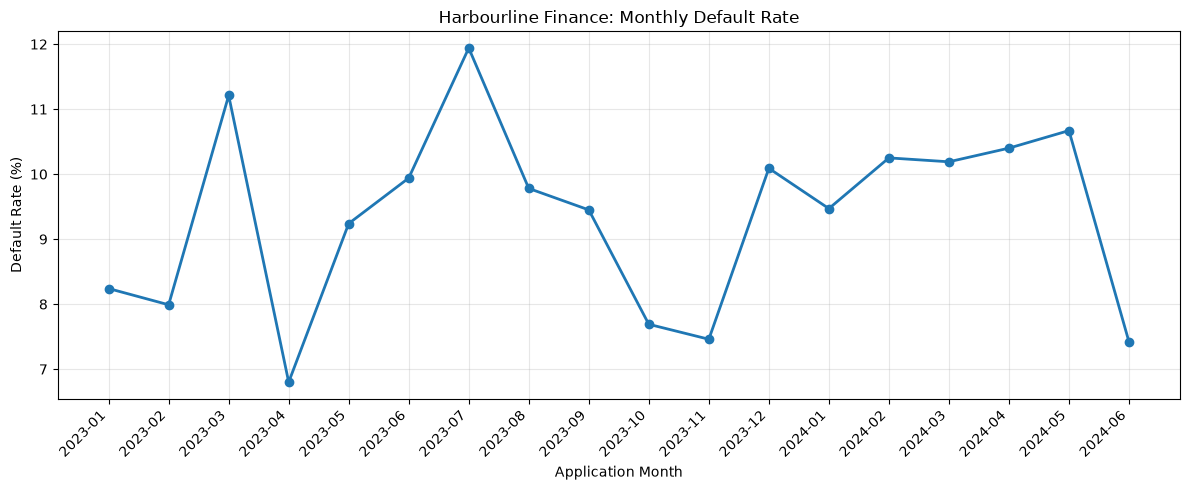

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_performance["application_period"].astype(str),
    monthly_performance["default_rate_pct"],
    marker="o",
    linewidth=2
)

plt.title("Harbourline Finance: Monthly Default Rate")
plt.xlabel("Application Month")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [60]:
# Compare the first half of 2023 with the first half of 2024

loans_clean["application_year"] = (
    loans_clean["application_month"].dt.year
)

loans_clean["application_month_num"] = (
    loans_clean["application_month"].dt.month
)

h1_data = loans_clean[
    (loans_clean["application_month_num"] <= 6)
    & (loans_clean["application_year"].isin([2023, 2024]))
].copy()

h1_comparison = (
    h1_data
    .groupby("application_year")
    .agg(
        total_loans=("loan_id", "count"),
        defaults=("default_12m", "sum"),
        default_rate=("default_12m", "mean")
    )
    .reset_index()
)

h1_comparison["default_rate_pct"] = (
    h1_comparison["default_rate"] * 100
).round(2)

display(h1_comparison)

,application_year,total_loans,defaults,default_rate,default_rate_pct
0,2023,3817,341,0.089337,8.93
1,2024,3848,374,0.097193,9.72


### First-Half Default Rate Comparison

The historical portfolio's default rate increased from 8.93% in H1 2023 to 9.72% in H1 2024, an increase of 0.79 percentage points. The number of defaults rose from 341 to 374, while the number of loans increased from 3,817 to 3,848.

This indicates a deterioration in observed credit performance during the first half of 2024. However, the comparison does not establish the underlying cause. Further analysis of borrower characteristics, lending channels, and credit-risk indicators is needed to identify segments associated with higher default rates.

From a business perspective, the increase warrants investigation because persistent deterioration could increase expected credit losses and reduce portfolio profitability.

In [61]:
# Borrower segments that carry the most risk
employment_risk = (
    loans_clean
    .groupby("employment_type")
    .agg(
        total_loans=("loan_id", "count"),
        defaults=("default_12m", "sum"),
        default_rate=("default_12m", "mean"),
        average_loan_amount=("loan_amount", "mean")
    )
    .reset_index()
)

employment_risk["default_rate_pct"] = (
    employment_risk["default_rate"] * 100
).round(2)

employment_risk["average_loan_amount"] = (
    employment_risk["average_loan_amount"]
).round(2)

display(
    employment_risk.sort_values(
        "default_rate",
        ascending=False
    )
)

,employment_type,total_loans,defaults,default_rate,average_loan_amount,default_rate_pct
1,Informal,1158,170,0.146805,8731.43,14.68
0,Contract,1672,178,0.106459,8306.94,10.65
3,Self-employed,2337,234,0.100128,8476.12,10.01
2,Salaried,6415,501,0.078098,9574.98,7.81


### Default Risk by Employment Type

The informal employment segment had the highest observed 12-month default rate at 14.68%, followed by contract workers at 10.65%, self-employed borrowers at 10.01%, and salaried borrowers at 7.81%.

Informal workers had a lower average loan amount than salaried borrowers, despite their substantially higher default rate. Salaried borrowers had the highest average loan amount and the lowest observed default rate among the four groups.

These findings suggest that employment type may be useful for understanding portfolio risk. However, the differences are descriptive and may reflect other borrower characteristics, including bureau scores, credit history, and affordability. Further analysis and multivariable modelling are required before using employment type to inform approval decisions.

The next step is to compare monetary losses and exposure across employment segments to determine whether the highest-default segment also contributes disproportionately to portfolio losses.

In [62]:
# default risk by lending channel
channel_risk = (
    loans_clean
    .groupby("channel")
    .agg(
        total_loans=("loan_id", "count"),
        defaults=("default_12m", "sum"),
        default_rate=("default_12m", "mean"),
        average_loan_amount=("loan_amount", "mean"),
        total_amount_lent=("loan_amount", "sum")
    )
    .reset_index()
)

channel_risk["default_rate_pct"] = (
    channel_risk["default_rate"] * 100
).round(2)

channel_risk["average_loan_amount"] = (
    channel_risk["average_loan_amount"]
).round(2)

channel_risk["total_amount_lent"] = (
    channel_risk["total_amount_lent"]
).round(2)

display(
    channel_risk.sort_values(
        "default_rate",
        ascending=False
    )
)

,channel,total_loans,defaults,default_rate,average_loan_amount,total_amount_lent,default_rate_pct
1,Broker,2292,257,0.112129,9115.36,20892400.0,11.21
2,Online,5792,531,0.091678,9072.39,52547300.0,9.17
0,Branch,3498,295,0.084334,9088.82,31792700.0,8.43


### Default Risk by Lending Channel

Broker-originated loans had the highest observed 12-month default rate at 11.21%, followed by Online at 9.17% and Branch at 8.43%. Broker performance was 2.78 percentage points worse than Branch performance.

Online lending represented the largest channel by volume, with 5,792 loans and total lending of 52,547,300. It also recorded the largest number of defaults, at 531. This demonstrates that portfolio risk should be assessed using both default rates and lending exposure.

The findings support further investigation of broker-originated loans and continued monitoring of the Online portfolio. However, channel differences may reflect differences in applicant risk profiles rather than a direct channel effect. Final lending decisions should therefore incorporate applicant-level risk estimates and expected-loss analysis.

In [67]:
# default risk by bureau-score band
# Group historical loans into bureau-score bands
score_bins = [539, 580, 620, 660, 700, 740, 780, 820]
score_labels = [
    "540-580",
    "581-620",
    "621-660",
    "661-700",
    "701-740",
    "741-780",
    "781-820"
]

loans_clean["bureau_score_band"] = pd.cut(
    loans_clean["bureau_score"],
    bins=score_bins,
    labels=score_labels,
    include_lowest=True
)

bureau_risk = (
    loans_clean
    .groupby("bureau_score_band", observed=False)
    .agg(
        total_loans=("loan_id", "count"),
        defaults=("default_12m", "sum"),
        default_rate=("default_12m", "mean"),
        average_loan_amount=("loan_amount", "mean")
    )
    .reset_index()
)

bureau_risk["default_rate_pct"] = (
    bureau_risk["default_rate"] * 100
).round(2)

bureau_risk["average_loan_amount"] = (
    bureau_risk["average_loan_amount"]
).round(2)

display(bureau_risk)

,bureau_score_band,total_loans,defaults,default_rate,average_loan_amount,default_rate_pct
0,540-580,1304,390,0.299080,9216.56,29.91
1,581-620,2617,382,0.145969,9171.95,14.60
2,621-660,3444,228,0.066202,8853.77,6.62
3,661-700,2576,63,0.024457,9252.60,2.45
4,701-740,1235,17,0.013765,9101.86,1.38
5,741-780,353,3,0.008499,9148.16,0.85
6,781-820,53,0,0.000000,7807.55,0.00


### Default Risk by Bureau-Score Band

Observed default rates declined across the historical bureau-score bands, from 29.91% for scores of 540–580 to 0.00% for scores of 781–820. The lowest band contained 1,304 loans and 390 defaults, while the highest band contained only 53 loans and no observed defaults.

The pattern indicates a strong relationship between bureau score and historical default outcomes. It supports further evaluation of bureau score as a predictor of probability of default.

However, the zero observed default rate in the highest band should not be interpreted as zero underlying risk because the sample is small. In addition, historical loans below the existing approval threshold of 540 are absent, limiting conclusions about previously rejected applicants.

The results motivate a comparison of the current bureau-score policy with a PD-based policy, using out-of-time model validation and expected-loss analysis before recommending a change.

In [68]:
# risk by credit utilisation
# Group loans into credit-utilisation bands
utilisation_bins = [-0.001, 0.30, 0.60, 0.80, 1.00, float("inf")]
utilisation_labels = [
    "0-30%",
    "31-60%",
    "61-80%",
    "81-100%",
    "Above 100%"
]

loans_clean["utilisation_band"] = pd.cut(
    loans_clean["credit_utilisation"],
    bins=utilisation_bins,
    labels=utilisation_labels,
    include_lowest=True
)

utilisation_risk = (
    loans_clean
    .groupby("utilisation_band", observed=False)
    .agg(
        total_loans=("loan_id", "count"),
        defaults=("default_12m", "sum"),
        default_rate=("default_12m", "mean")
    )
    .reset_index()
)

utilisation_risk["default_rate_pct"] = (
    utilisation_risk["default_rate"] * 100
).round(2)

display(utilisation_risk)

,utilisation_band,total_loans,defaults,default_rate,default_rate_pct
0,0-30%,2758,127,0.046048,4.60
1,31-60%,5673,509,0.089723,8.97
2,61-80%,2319,293,0.126348,12.63
3,81-100%,788,141,0.178934,17.89
4,Above 100%,44,13,0.295455,29.55


### Default Risk by Credit Utilisation

Observed default rates increased consistently across credit-utilisation bands. The default rate rose from 4.60% among borrowers with utilisation of 0–30% to 17.89% among borrowers with utilisation of 81–100%. The group above 100% utilisation had the highest observed default rate at 29.55%, based on 44 loans.

This pattern suggests that credit utilisation may be a useful predictor of probability of default. However, the small sample above 100% utilisation limits the precision of its observed default rate, and the descriptive analysis does not establish causation.

Credit utilisation will be retained as a candidate predictor for model development. Its contribution will be assessed alongside bureau score, delinquency history, affordability indicators, and other application-time variables.

In [69]:
# default risk by delinquency history
delinquency_risk = (
    loans_clean
    .groupby("delinquencies_2y")
    .agg(
        total_loans=("loan_id", "count"),
        defaults=("default_12m", "sum"),
        default_rate=("default_12m", "mean")
    )
    .reset_index()
)

delinquency_risk["default_rate_pct"] = (
    delinquency_risk["default_rate"] * 100
).round(2)

display(delinquency_risk)

,delinquencies_2y,total_loans,defaults,default_rate,default_rate_pct
0,0,6634,273,0.041152,4.12
1,1,2722,299,0.109846,10.98
2,2,1340,250,0.186567,18.66
3,3,561,141,0.251337,25.13
4,4,220,64,0.290909,29.09
5,5,67,31,0.462687,46.27
6,6,31,20,0.645161,64.52
7,7,5,4,0.800000,80.00
8,8,1,1,1.000000,100.00
9,9,1,0,0.000000,0.00


### Default Risk by Delinquency History

The observed 12-month default rate increased from 4.12% among borrowers with no recorded delinquencies in the preceding two years to 18.66% among borrowers with two delinquencies and 29.09% among borrowers with four.

The pattern suggests that prior delinquency history is an important candidate predictor of probability of default. However, the groups with five or more delinquencies contain relatively few loans, making their observed default rates unstable. These rates should not be treated as precise estimates of underlying risk.

The `delinquencies_2y` variable will be retained as a candidate predictor and evaluated alongside bureau score, credit utilisation, and other application-time characteristics during model development.

In [71]:
# default risk by debt-to-income ratio
# Group historical loans into debt-to-income bands

dti_bins = [0, 0.20, 0.30, 0.40, 0.50, 1.00]
dti_labels = [
    "0-20%",
    "21-30%",
    "31-40%",
    "41-50%",
    "Above 50%"
]

loans_clean["dti_band"] = pd.cut(
    loans_clean["debt_to_income"],
    bins=dti_bins,
    labels=dti_labels,
    include_lowest=True
)

dti_risk = (
    loans_clean
    .groupby("dti_band", observed=False)
    .agg(
        total_loans=("loan_id", "count"),
        defaults=("default_12m", "sum"),
        default_rate=("default_12m", "mean")
    )
    .reset_index()
)

dti_risk["default_rate_pct"] = (
    dti_risk["default_rate"] * 100
).round(2)

display(dti_risk)

,dti_band,total_loans,defaults,default_rate,default_rate_pct
0,0-20%,2097,141,0.067239,6.72
1,21-30%,2957,240,0.081163,8.12
2,31-40%,2790,243,0.087097,8.71
3,41-50%,1952,204,0.104508,10.45
4,Above 50%,1786,255,0.142777,14.28


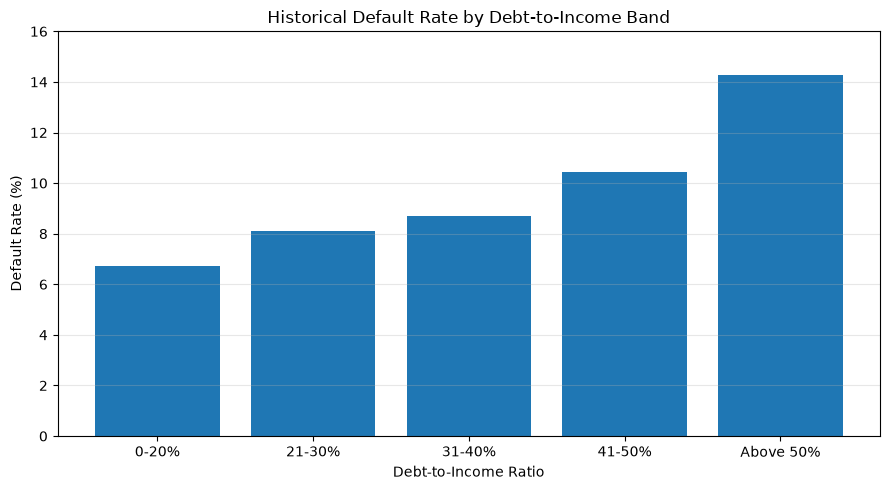

In [72]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    dti_risk["dti_band"].astype(str),
    dti_risk["default_rate_pct"]
)

plt.title("Historical Default Rate by Debt-to-Income Band")
plt.xlabel("Debt-to-Income Ratio")
plt.ylabel("Default Rate (%)")
plt.ylim(0, 16)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Default Risk by Debt-to-Income Ratio

**Objective:** Assess how borrowers' existing debt obligations relate to historical loan defaults.

**Findings:** The historical default rate increased consistently across the five DTI bands, rising from 6.72% among borrowers with DTI of 20% or below to 14.28% among borrowers with DTI above 50%. The highest-DTI group had approximately 2.13 times the default rate of the lowest-DTI group.

**Business implication:** DTI is a candidate predictor for the probability-of-default (PD) model. It may help distinguish applicants with different levels of repayment capacity.

**Limitation:** These results are descriptive. DTI should be evaluated alongside other risk indicators, and its incremental predictive value should be tested during modelling.

In [73]:
# default risk by loan purpose
purpose_risk = (
    loans_clean.groupby("loan_purpose", observed=True)
    .agg(
        total_loans=("loan_id", "count"),
        defaults=("default_12m", "sum"),
        default_rate=("default_12m", "mean"),
        avg_loan_amount=("loan_amount", "mean")
    )
    .reset_index()
)

purpose_risk["default_rate_pct"] = (
    purpose_risk["default_rate"] * 100
).round(2)

purpose_risk["avg_loan_amount"] = (
    purpose_risk["avg_loan_amount"]
).round(2)

purpose_risk = purpose_risk.sort_values(
    "default_rate_pct", ascending=False
)

display(purpose_risk)

,loan_purpose,total_loans,defaults,default_rate,avg_loan_amount,default_rate_pct
2,Education,1154,120,0.103986,8779.81,10.40
1,Debt consolidation,3950,404,0.102278,9095.06,10.23
4,Medical,955,91,0.095288,9038.01,9.53
0,Business,1199,109,0.090909,9098.42,9.09
3,Home improvement,1773,152,0.085730,9042.92,8.57
6,Vehicle,1363,111,0.081438,9134.78,8.14
5,Other,1188,96,0.080808,9386.28,8.08


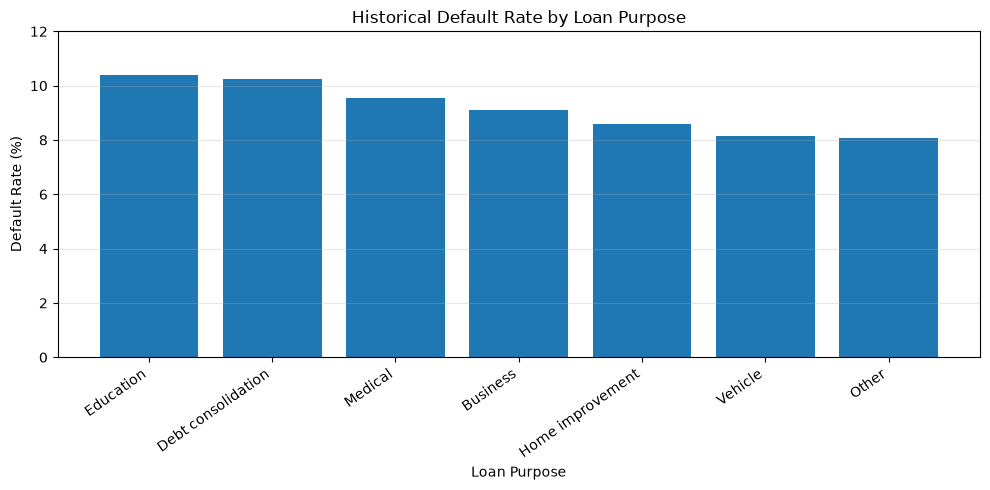

In [74]:
import matplotlib.pyplot as plt

purpose_chart = purpose_risk.sort_values(
    "default_rate_pct", ascending=False
)

plt.figure(figsize=(10, 5))

plt.bar(
    purpose_chart["loan_purpose"],
    purpose_chart["default_rate_pct"]
)

plt.title("Historical Default Rate by Loan Purpose")
plt.xlabel("Loan Purpose")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 12)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Default Risk by Loan Purpose

**Objective:** Assess whether historical default rates differ across loan purposes.

**Findings:** Education loans had the highest observed default rate at 10.40%, followed by debt consolidation at 10.23%. The Other category had the lowest rate at 8.08%. Debt consolidation represented the largest segment, with 3,950 loans and 404 defaults.

**Business implication:** Loan purpose may provide supplementary information for the probability-of-default model. Debt consolidation deserves attention because of its contribution to total defaults, while Education has the highest observed default rate.

**Limitation:** These are descriptive differences and do not establish that loan purpose causes default. Its predictive value should be evaluated alongside stronger candidate predictors during model development.

In [75]:
# default risk by loan_term
term_risk = (
    loans_clean.groupby("term_months", observed=True)
    .agg(
        total_loans=("loan_id", "count"),
        defaults=("default_12m", "sum"),
        default_rate=("default_12m", "mean"),
        avg_loan_amount=("loan_amount", "mean")
    )
    .reset_index()
    .sort_values("term_months")
)

term_risk["default_rate_pct"] = (
    term_risk["default_rate"] * 100
).round(2)

term_risk["avg_loan_amount"] = (
    term_risk["avg_loan_amount"]
).round(2)

display(term_risk)

,term_months,total_loans,defaults,default_rate,avg_loan_amount,default_rate_pct
0,12,2406,209,0.086866,8945.72,8.69
1,24,4028,359,0.089126,8921.25,8.91
2,36,3419,349,0.102077,9289.94,10.21
3,48,1729,166,0.096009,9260.79,9.60


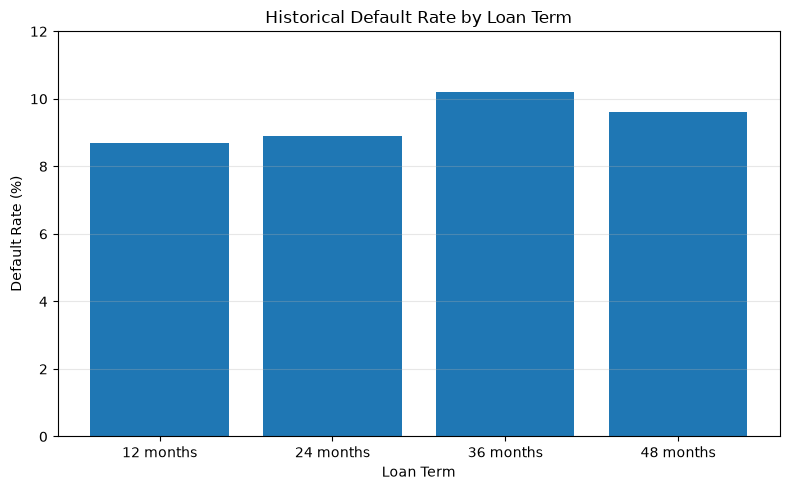

In [76]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    term_risk["term_months"].astype(str) + " months",
    term_risk["default_rate_pct"]
)

plt.title("Historical Default Rate by Loan Term")
plt.xlabel("Loan Term")
plt.ylabel("Default Rate (%)")
plt.ylim(0, 12)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Default Risk by Loan Term

**Objective:** Assess the relationship between repayment duration and historical loan defaults.

**Findings:** The 36-month term recorded the highest default rate at 10.21%, while the 12-month term recorded the lowest at 8.69%. The relationship was not linear because the default rate declined to 9.60% for 48-month loans. The 24-month term had the largest portfolio volume, with 4,028 loans.

**Business implication:** Loan term is a candidate predictor for the PD model, but its contribution should be evaluated alongside borrower risk characteristics and loan amount.

**Limitation:** These descriptive results do not establish that loan term causes default. Differences in borrower selection and other loan characteristics may explain part of the observed variation.

In [77]:
# default risk by region
region_risk = (
    loans_clean.groupby("region", observed=True)
    .agg(
        total_loans=("loan_id", "count"),
        defaults=("default_12m", "sum"),
        default_rate=("default_12m", "mean"),
        total_amount_lent=("loan_amount", "sum")
    )
    .reset_index()
)

region_risk["default_rate_pct"] = (
    region_risk["default_rate"] * 100
).round(2)

region_risk["total_amount_lent"] = (
    region_risk["total_amount_lent"]
).round(2)

region_risk = region_risk.sort_values(
    "default_rate_pct", ascending=False
)

display(region_risk)

,region,total_loans,defaults,default_rate,total_amount_lent,default_rate_pct
1,Inland,2115,211,0.099764,19221100.0,9.98
4,Rural,1385,135,0.097473,12720200.0,9.75
2,Metro North,2878,278,0.096595,26928400.0,9.66
0,Coastal,2257,200,0.088613,20214700.0,8.86
3,Metro South,2947,259,0.087886,26148000.0,8.79


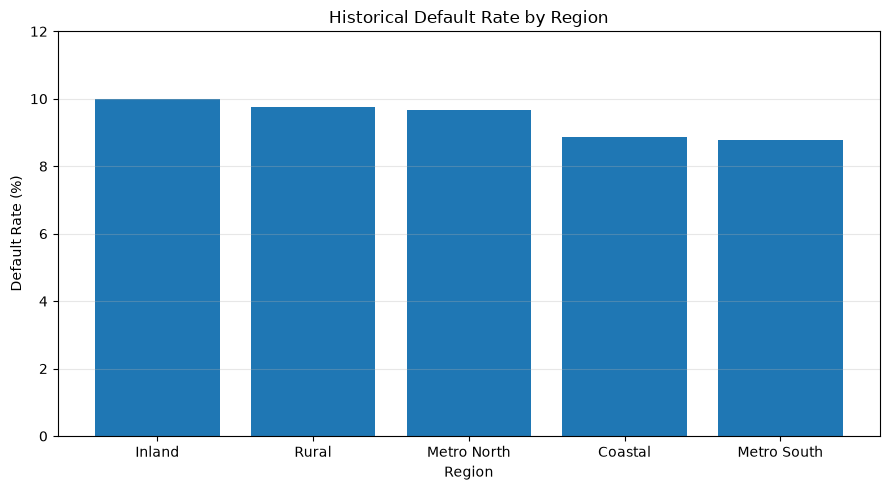

In [78]:
import matplotlib.pyplot as plt

region_chart = region_risk.sort_values(
    "default_rate_pct", ascending=False
)

plt.figure(figsize=(9, 5))

plt.bar(
    region_chart["region"],
    region_chart["default_rate_pct"]
)

plt.title("Historical Default Rate by Region")
plt.xlabel("Region")
plt.ylabel("Default Rate (%)")
plt.ylim(0, 12)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Default Risk by Region

**Objective:** Examine differences in historical default rates and lending exposure across regions.

**Findings:** Inland recorded the highest default rate at 9.98%, while Metro South recorded the lowest at 8.79%. The difference was 1.19 percentage points. Metro North contributed the highest number of defaults (278) and the largest total amount lent (26,928,400).

**Business implication:** Region may provide supplementary information for portfolio monitoring and PD modelling. However, its predictive contribution should be tested alongside customer and loan characteristics.

**Limitation:** These are descriptive differences and do not establish that geography causes default. Regional variables should be assessed for fairness and potential proxy effects before being used in credit decisions.

In [79]:
# Interest rate & default risk
rate_bins = [0, 10, 15, 20, 25, 100]
rate_labels = [
    "Below 10%",
    "10-15%",
    "15-20%",
    "20-25%",
    "Above 25%"
]

loans_clean["interest_rate_band"] = pd.cut(
    loans_clean["interest_rate"],
    bins=rate_bins,
    labels=rate_labels,
    include_lowest=True,
    right=False
)

interest_rate_risk = (
    loans_clean.groupby(
        "interest_rate_band", observed=False
    )
    .agg(
        total_loans=("loan_id", "count"),
        defaults=("default_12m", "sum"),
        default_rate=("default_12m", "mean")
    )
    .reset_index()
)

interest_rate_risk["default_rate_pct"] = (
    interest_rate_risk["default_rate"] * 100
).round(2)

display(interest_rate_risk)

,interest_rate_band,total_loans,defaults,default_rate,default_rate_pct
0,Below 10%,11582,1083,0.093507,9.35
1,10-15%,0,0,NaN,NaN
2,15-20%,0,0,NaN,NaN
3,20-25%,0,0,NaN,NaN
4,Above 25%,0,0,NaN,NaN


In [81]:
rate_bins = [0, 0.10, 0.15, 0.20, 0.25, float("inf")]

rate_labels = [
    "Below 10%",
    "10–15%",
    "15–20%",
    "20–25%",
    "Above 25%"
]

loans_clean["interest_rate_band"] = pd.cut(
    loans_clean["interest_rate"],
    bins=rate_bins,
    labels=rate_labels,
    include_lowest=True,
    right=False
)

interest_rate_risk = (
    loans_clean.groupby("interest_rate_band", observed=False)
    .agg(
        total_loans=("loan_id", "count"),
        defaults=("default_12m", "sum"),
        default_rate=("default_12m", "mean")
    )
    .reset_index()
)

interest_rate_risk["default_rate_pct"] = (
    interest_rate_risk["default_rate"] * 100
).round(2)

display(interest_rate_risk)

,interest_rate_band,total_loans,defaults,default_rate,default_rate_pct
0,Below 10%,245,2,0.008163,0.82
1,10–15%,3579,73,0.020397,2.04
2,15–20%,3765,231,0.061355,6.14
3,20–25%,2644,379,0.143343,14.33
4,Above 25%,1349,398,0.295033,29.50


### Default Risk by Interest Rate

**Objective:** Examine the association between contractual interest rates and historical loan defaults.

**Findings:** The observed default rate increased from 0.82% for loans below 10% interest to 29.50% for loans above 25%. The above-25% band contributed 398 defaults from 1,349 loans, the largest number of defaults among the interest-rate bands.

**Business implication:** Interest rate is informative for understanding historical portfolio risk and may support analysis of risk-based pricing and profitability.

**Limitation:** The association does not establish causation. Interest rates may reflect the lender's original assessment of borrower risk, creating potential endogeneity if used as a predictor. Its timing and availability at the credit decision must be verified before considering it for the PD model.

In [84]:
# EDA hypothesis summary
eda_summary = pd.DataFrame([
    {
        "factor": "Bureau score",
        "key_finding": "Default rate falls as score increases",
        "model_note": "Strong candidate predictor"
    },
    {
        "factor": "Credit utilisation",
        "key_finding": "Default rate rises across utilisation bands",
        "model_note": "Strong candidate predictor"
    },
    {
        "factor": "Delinquencies (2 years)",
        "key_finding": "Default rates generally rise with delinquency count",
        "model_note": "Strong candidate predictor; high counts are sparse"
    },
    {
        "factor": "Debt-to-income",
        "key_finding": "Default rate rises from 6.72% to 14.28%",
        "model_note": "Candidate predictor"
    },
    {
        "factor": "Employment type",
        "key_finding": "Informal employment has the highest observed rate",
        "model_note": "Candidate predictor"
    },
    {
        "factor": "Channel",
        "key_finding": "Broker channel has the highest observed rate",
        "model_note": "Candidate predictor; investigate channel effects"
    },
    {
        "factor": "Loan purpose",
        "key_finding": "Rates range from 8.08% to 10.40%",
        "model_note": "Supplementary candidate predictor"
    },
    {
        "factor": "Loan term",
        "key_finding": "36-month loans have the highest observed rate",
        "model_note": "Candidate predictor"
    },
    {
        "factor": "Region",
        "key_finding": "Rates range from 8.79% to 9.98%",
        "model_note": "Test incremental value and fairness"
    },
    {
        "factor": "Interest rate",
        "key_finding": "Rates rise from 0.82% to 29.50% across bands",
        "model_note": "Exclude provisionally until timing is verified"
    }
])

display(eda_summary)

,factor,key_finding,model_note
0,Bureau score,Default rate falls as score increases,Strong candidate predictor
1,Credit utilisation,Default rate rises across utilisation bands,Strong candidate predictor
2,Delinquencies (2 years),Default rates generally rise with delinquency ...,Strong candidate predictor; high counts are sp...
3,Debt-to-income,Default rate rises from 6.72% to 14.28%,Candidate predictor
4,Employment type,Informal employment has the highest observed rate,Candidate predictor
5,Channel,Broker channel has the highest observed rate,Candidate predictor; investigate channel effects
6,Loan purpose,Rates range from 8.08% to 10.40%,Supplementary candidate predictor
7,Loan term,36-month loans have the highest observed rate,Candidate predictor
8,Region,Rates range from 8.79% to 9.98%,Test incremental value and fairness
9,Interest rate,Rates rise from 0.82% to 29.50% across bands,Exclude provisionally until timing is verified


In [86]:
eda_summary.to_csv(r"C:\Users\Administrator\Desktop\harborline_credit_risk\outputs\eda_outputs\hypothesis_summary.csv", index=True)